# Graph-Based Empathic Environment - Testing

This notebook tests the graph-based multi-agent environment where:
- Agents are fixed nodes in a **static directed social graph**
- A→B means agent A perceives agent B's emotion
- Each agent sees the **mean emotion** of agents it's connected to
- Reward for consuming agents: `(1-α) × personal + α × mean_neighbor_emotion`
- Waiting / failed agents get reward = 0.0

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

from social_graph import SocialGraph
from resource_pool import ResourcePool
from agent_graph import GraphDQNAgent, Agent
from env_graph import EmpathicGraphEnv

NUM_AGENTS = 6
SEED = 42

print("All imports successful!")

All imports successful!


## 1. Directed Graph Visualization

Create and visualize the directed social graph. Arrows show perception: A→B means A perceives B's emotion.

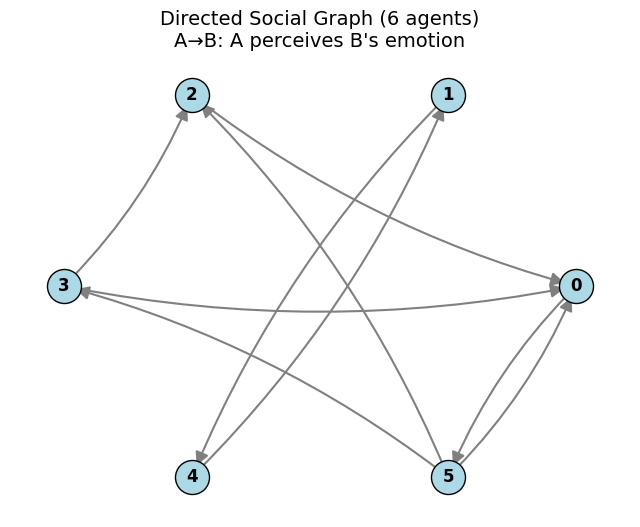


Adjacency Matrix (row i, col j = 1 means agent i perceives agent j):
[[0 0 0 0 0 1]
 [0 0 0 0 1 0]
 [1 0 0 0 0 0]
 [1 0 1 0 0 0]
 [0 1 0 0 0 0]
 [1 0 1 1 0 0]]

Per-agent connections:
  Agent 0 perceives: [5] (out-degree: 1)
  Agent 1 perceives: [4] (out-degree: 1)
  Agent 2 perceives: [0] (out-degree: 1)
  Agent 3 perceives: [0, 2] (out-degree: 2)
  Agent 4 perceives: [1] (out-degree: 1)
  Agent 5 perceives: [0, 2, 3] (out-degree: 3)

Graph density: 0.30
Average degree: 1.5


In [2]:
# Create and visualize directed graph
graph = SocialGraph(
    num_agents=NUM_AGENTS,
    graph_type='directed_random',
    edge_probability=0.4,
    seed=SEED
)

fig = graph.draw_graph(title=f'Directed Social Graph ({NUM_AGENTS} agents)\nA→B: A perceives B\'s emotion')
plt.show()

print(f"\nAdjacency Matrix (row i, col j = 1 means agent i perceives agent j):")
print(graph.adjacency.astype(int))

print(f"\nPer-agent connections:")
for i in range(NUM_AGENTS):
    neighbors = graph.get_neighbors(i)
    print(f"  Agent {i} perceives: {neighbors} (out-degree: {len(neighbors)})")

print(f"\nGraph density: {graph.get_density():.2f}")
print(f"Average degree: {graph.get_average_degree():.1f}")

## 2. Single Episode Run

Run one episode to verify the environment mechanics and reward structure.

In [3]:
# Create environment with directed graph
env = EmpathicGraphEnv(
    num_agents=NUM_AGENTS,
    initial_pool=50,
    max_pool_capacity=100,
    regeneration_rate=1.0,
    regeneration_mode='constant',
    env_type='stochastic',
    graph_type='directed_random',
    edge_probability=0.4,
    alpha=0.5,
    beta=0.5,
    max_steps=200
)

# Create agents
agents = [
    GraphDQNAgent(agent_id=i, observation_dim=4, epsilon=0.5)
    for i in range(NUM_AGENTS)
]
env.set_agents(agents)

# Run episode
obs, info = env.reset(seed=SEED)
for agent, o in zip(agents, obs):
    agent.reset(observation=o)

# Verify graph is the one we expect
print("Graph adjacency at start:")
print(env.graph.adjacency.astype(int))
adj_start = env.graph.get_adjacency_matrix()

episode_data = {
    'pool_levels': [],
    'rewards': [[] for _ in range(NUM_AGENTS)],
    'consumptions': [0] * NUM_AGENTS,
    'satisfactions': [[] for _ in range(NUM_AGENTS)],
    'emotions': [[] for _ in range(NUM_AGENTS)],
}

for step in range(env.max_steps):
    episode_data['pool_levels'].append(env.pool.current)
    for i in range(NUM_AGENTS):
        episode_data['satisfactions'][i].append(agents[i].get_satisfaction())
        episode_data['emotions'][i].append(agents[i].get_emotion())

    actions = [agent.select_action(obs[i], training=True) for i, agent in enumerate(agents)]
    next_obs, rewards, terminated, truncated, info = env.step(actions)

    for i in range(NUM_AGENTS):
        episode_data['rewards'][i].append(rewards[i])
        if info['consumed'][i]:
            episode_data['consumptions'][i] += 1

    for i, agent in enumerate(agents):
        agent.step(next_obs[i], rewards[i], terminated or truncated)

    obs = next_obs
    if terminated or truncated:
        break

# Verify graph stayed static
adj_end = env.graph.get_adjacency_matrix()
assert np.array_equal(adj_start, adj_end), "Graph changed during episode!"
print("\nGraph stayed STATIC throughout episode (verified)")

print(f"\nEpisode finished at step {step + 1} ({'terminated - pool depleted' if terminated else 'truncated - max steps'})")
print(f"Final pool level: {env.pool.current:.2f}")
print(f"Consumptions per agent: {episode_data['consumptions']}")
print(f"Total rewards per agent: {[f'{sum(r):.3f}' for r in episode_data['rewards']]}")

GraphDQNAgent using device: cpu
Graph adjacency at start:
[[0 0 0 0 0 1]
 [0 0 0 0 1 0]
 [1 0 0 0 0 0]
 [1 0 1 0 0 0]
 [0 1 0 0 0 0]
 [1 0 1 1 0 0]]

Graph stayed STATIC throughout episode (verified)

Episode finished at step 82 (terminated - pool depleted)
Final pool level: 0.00
Consumptions per agent: [8, 13, 8, 4, 7, 10]
Total rewards per agent: ['0.700', '-3.375', '0.475', '-0.800', '-1.100', '-1.492']


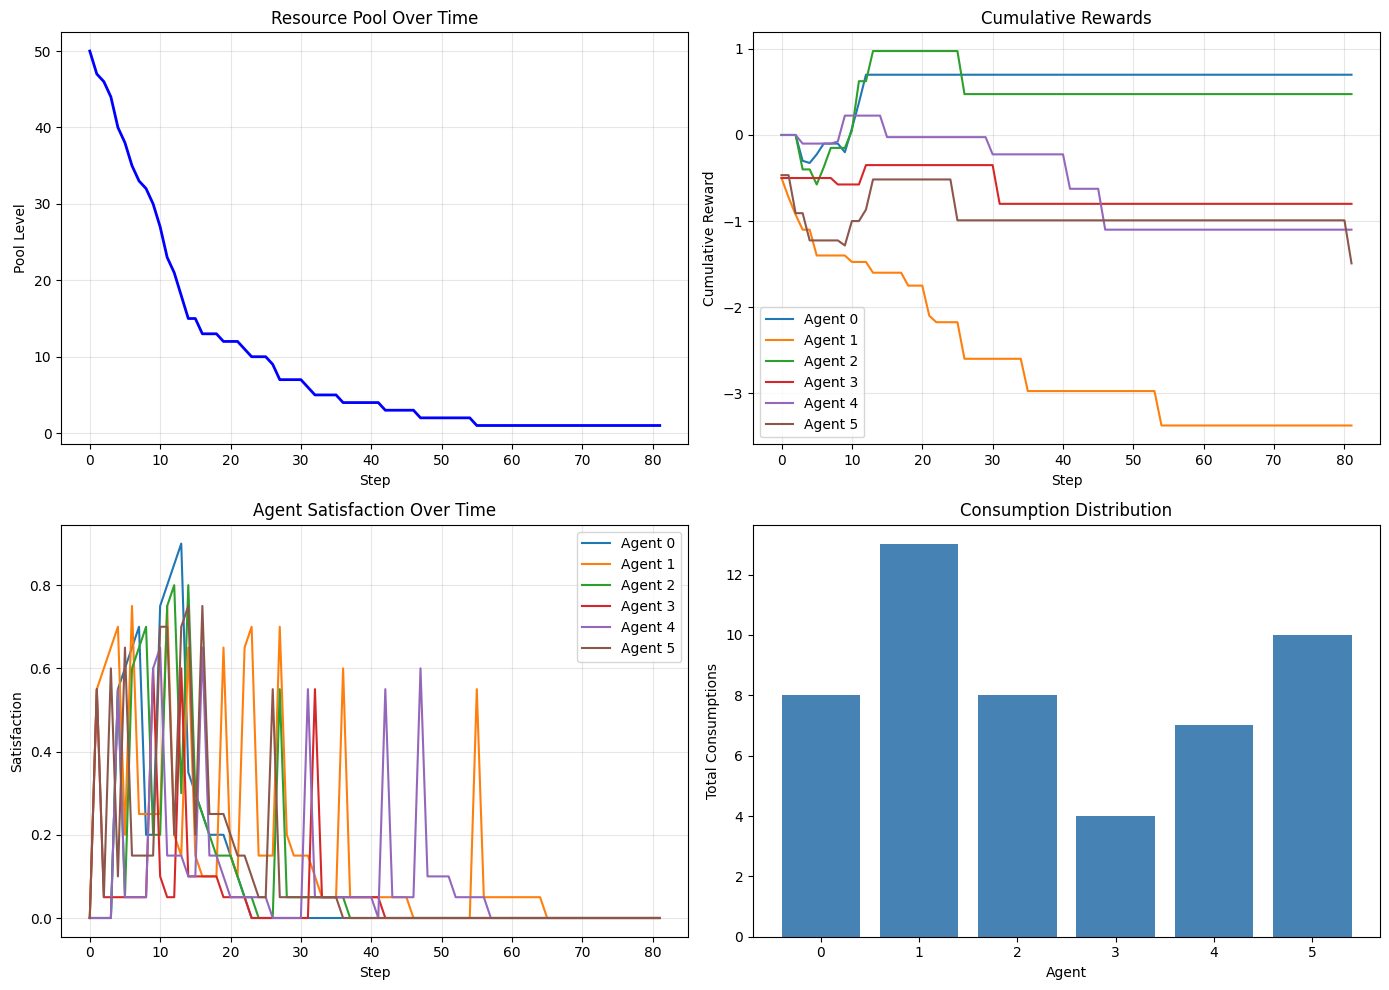

In [4]:
# Visualize single episode
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Pool level over time
ax1 = axes[0, 0]
ax1.plot(episode_data['pool_levels'], 'b-', linewidth=2)
ax1.set_xlabel('Step')
ax1.set_ylabel('Pool Level')
ax1.set_title('Resource Pool Over Time')
ax1.grid(True, alpha=0.3)

# Cumulative rewards
ax2 = axes[0, 1]
for i in range(NUM_AGENTS):
    cumulative = np.cumsum(episode_data['rewards'][i])
    ax2.plot(cumulative, label=f'Agent {i}')
ax2.set_xlabel('Step')
ax2.set_ylabel('Cumulative Reward')
ax2.set_title('Cumulative Rewards')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Satisfaction over time
ax3 = axes[1, 0]
for i in range(NUM_AGENTS):
    ax3.plot(episode_data['satisfactions'][i], label=f'Agent {i}')
ax3.set_xlabel('Step')
ax3.set_ylabel('Satisfaction')
ax3.set_title('Agent Satisfaction Over Time')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Consumption bar chart
ax4 = axes[1, 1]
ax4.bar(range(NUM_AGENTS), episode_data['consumptions'], color='steelblue')
ax4.set_xlabel('Agent')
ax4.set_ylabel('Total Consumptions')
ax4.set_title('Consumption Distribution')
ax4.set_xticks(range(NUM_AGENTS))

plt.tight_layout()
plt.show()

## 3. Empathic vs Non-Empathic Comparison

Compare α=0.0 (selfish) vs α=0.5 (empathic) using the same directed graph structure.

In [5]:
def compute_gini(values):
    """Compute Gini coefficient."""
    values = np.array(values, dtype=float)
    if len(values) == 0 or np.sum(values) == 0:
        return 0.0
    sorted_values = np.sort(values)
    n = len(sorted_values)
    index = np.arange(1, n + 1)
    return (2 * np.sum(index * sorted_values) - (n + 1) * np.sum(sorted_values)) / (n * np.sum(sorted_values))


def run_episode(env, agents, seed=None):
    """Run single episode and return metrics."""
    obs, _ = env.reset(seed=seed)
    for agent, o in zip(agents, obs):
        agent.reset(observation=o)

    consumptions = [0] * len(agents)
    total_rewards = [0.0] * len(agents)
    episode_length = 0

    for step in range(env.max_steps):
        actions = [agent.select_action(obs[i], training=True) for i, agent in enumerate(agents)]
        next_obs, rewards, terminated, truncated, info = env.step(actions)

        for i in range(len(agents)):
            total_rewards[i] += rewards[i]
            if info['consumed'][i]:
                consumptions[i] += 1

        for i, agent in enumerate(agents):
            agent.step(next_obs[i], rewards[i], terminated or truncated)

        obs = next_obs
        episode_length = step + 1
        if terminated or truncated:
            break

    final_satisfactions = [agent.get_satisfaction() for agent in agents]

    return {
        'consumptions': consumptions,
        'total_rewards': total_rewards,
        'final_satisfactions': final_satisfactions,
        'gini_consumption': compute_gini(consumptions),
        'gini_satisfaction': compute_gini(final_satisfactions),
        'total_consumption': sum(consumptions),
        'final_pool': env.pool.get_level(),
        'episode_length': episode_length,
    }

In [6]:
# Run comparison experiment
num_episodes = 30

results = {'empathic': [], 'non_empathic': []}

for condition, alpha_val in [('non_empathic', 0.0), ('empathic', 0.5)]:
    print(f"\nRunning {condition} condition (alpha={alpha_val})...")

    env = EmpathicGraphEnv(
        num_agents=NUM_AGENTS,
        initial_pool=50,
        max_pool_capacity=100,
        regeneration_rate=1.0,
        regeneration_mode='constant',
        env_type='stochastic',
        graph_type='directed_random',
        edge_probability=0.4,
        alpha=alpha_val,
        beta=0.5,
        max_steps=200
    )

    agents = [
        GraphDQNAgent(agent_id=i, observation_dim=4, epsilon=1.0, epsilon_decay=0.99)
        for i in range(NUM_AGENTS)
    ]
    env.set_agents(agents)

    for ep in range(num_episodes):
        metrics = run_episode(env, agents, seed=SEED + ep)
        results[condition].append(metrics)

        if (ep + 1) % 10 == 0:
            print(f"  Episode {ep + 1}/{num_episodes}")

print("\nDone!")


Running non_empathic condition (alpha=0.0)...
GraphDQNAgent using device: cpu
  Episode 10/30
  Episode 20/30
  Episode 30/30

Running empathic condition (alpha=0.5)...
GraphDQNAgent using device: cpu
  Episode 10/30
  Episode 20/30
  Episode 30/30

Done!


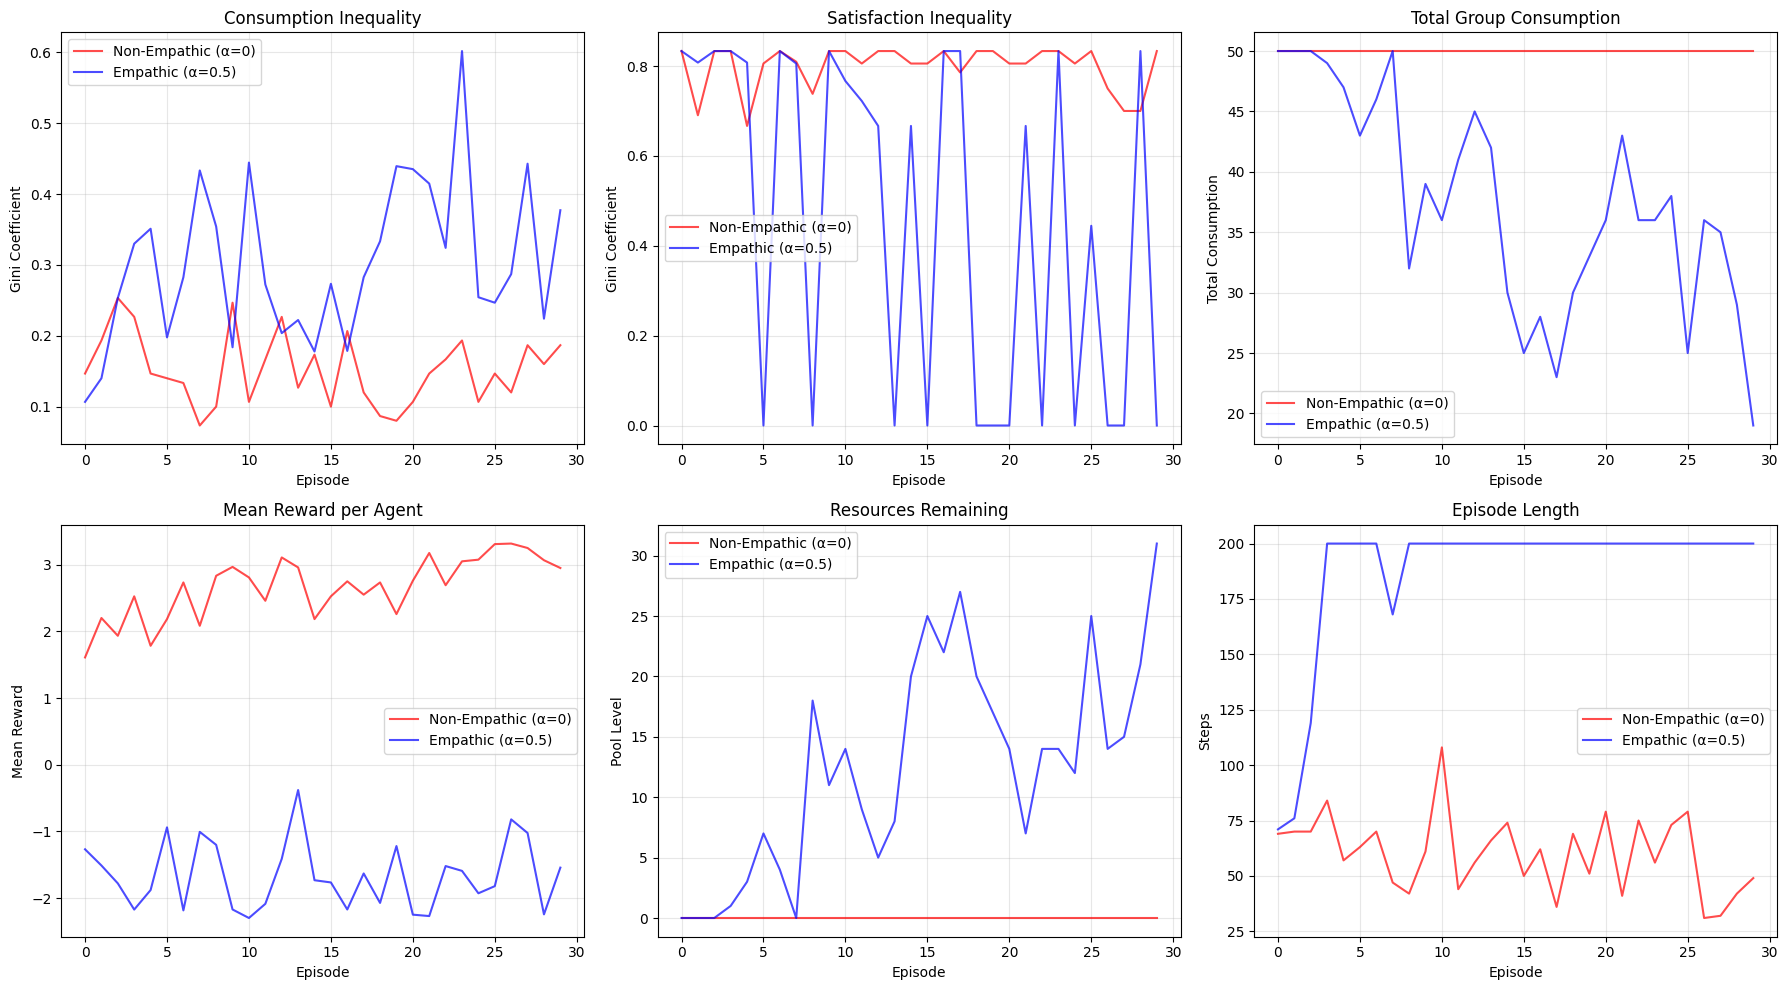

In [7]:
# Extract metrics
gini_consumption = {k: [r['gini_consumption'] for r in v] for k, v in results.items()}
gini_satisfaction = {k: [r['gini_satisfaction'] for r in v] for k, v in results.items()}
total_consumption = {k: [r['total_consumption'] for r in v] for k, v in results.items()}
mean_rewards = {k: [np.mean(r['total_rewards']) for r in v] for k, v in results.items()}
final_pool = {k: [r['final_pool'] for r in v] for k, v in results.items()}
episode_length = {k: [r['episode_length'] for r in v] for k, v in results.items()}

# Line plots over episodes
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

plot_configs = [
    ('Consumption Inequality', 'Gini Coefficient', gini_consumption),
    ('Satisfaction Inequality', 'Gini Coefficient', gini_satisfaction),
    ('Total Group Consumption', 'Total Consumption', total_consumption),
    ('Mean Reward per Agent', 'Mean Reward', mean_rewards),
    ('Resources Remaining', 'Pool Level', final_pool),
    ('Episode Length', 'Steps', episode_length),
]

for ax, (title, ylabel, data) in zip(axes.flatten(), plot_configs):
    ax.plot(data['non_empathic'], 'r-', alpha=0.7, label='Non-Empathic (α=0)')
    ax.plot(data['empathic'], 'b-', alpha=0.7, label='Empathic (α=0.5)')
    ax.set_xlabel('Episode')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Summary statistics
print("=" * 60)
print("SUMMARY STATISTICS")
print("=" * 60)

all_metrics = {
    'Gini Consumption': gini_consumption,
    'Gini Satisfaction': gini_satisfaction,
    'Total Consumption': total_consumption,
    'Mean Reward': mean_rewards,
    'Resources Remaining': final_pool,
    'Episode Length': episode_length,
}

for condition in ['non_empathic', 'empathic']:
    print(f"\n{condition.upper()}:")
    for name, data in all_metrics.items():
        print(f"  {name:22s}: mean={np.mean(data[condition]):.3f}, std={np.std(data[condition]):.3f}")

SUMMARY STATISTICS

NON_EMPATHIC:
  Gini Consumption      : mean=0.152, std=0.049
  Gini Satisfaction     : mean=0.799, std=0.049
  Total Consumption     : mean=50.000, std=0.000
  Mean Reward           : mean=2.661, std=0.453
  Resources Remaining   : mean=0.000, std=0.000
  Episode Length        : mean=60.200, std=17.011

EMPATHIC:
  Gini Consumption      : mean=0.302, std=0.110
  Gini Satisfaction     : mean=0.462, std=0.385
  Total Consumption     : mean=37.400, std=8.716
  Mean Reward           : mean=-1.664, std=0.498
  Resources Remaining   : mean=12.600, std=8.716
  Episode Length        : mean=187.800, std=34.223


C:\Users\evann\AppData\Local\Temp\ipykernel_19716\1499644162.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\evann\AppData\Local\Temp\ipykernel_19716\1499644162.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\evann\AppData\Local\Temp\ipykernel_19716\1499644162.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\evann\AppData\Local\Temp\ipykernel_19716\1499644162.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3

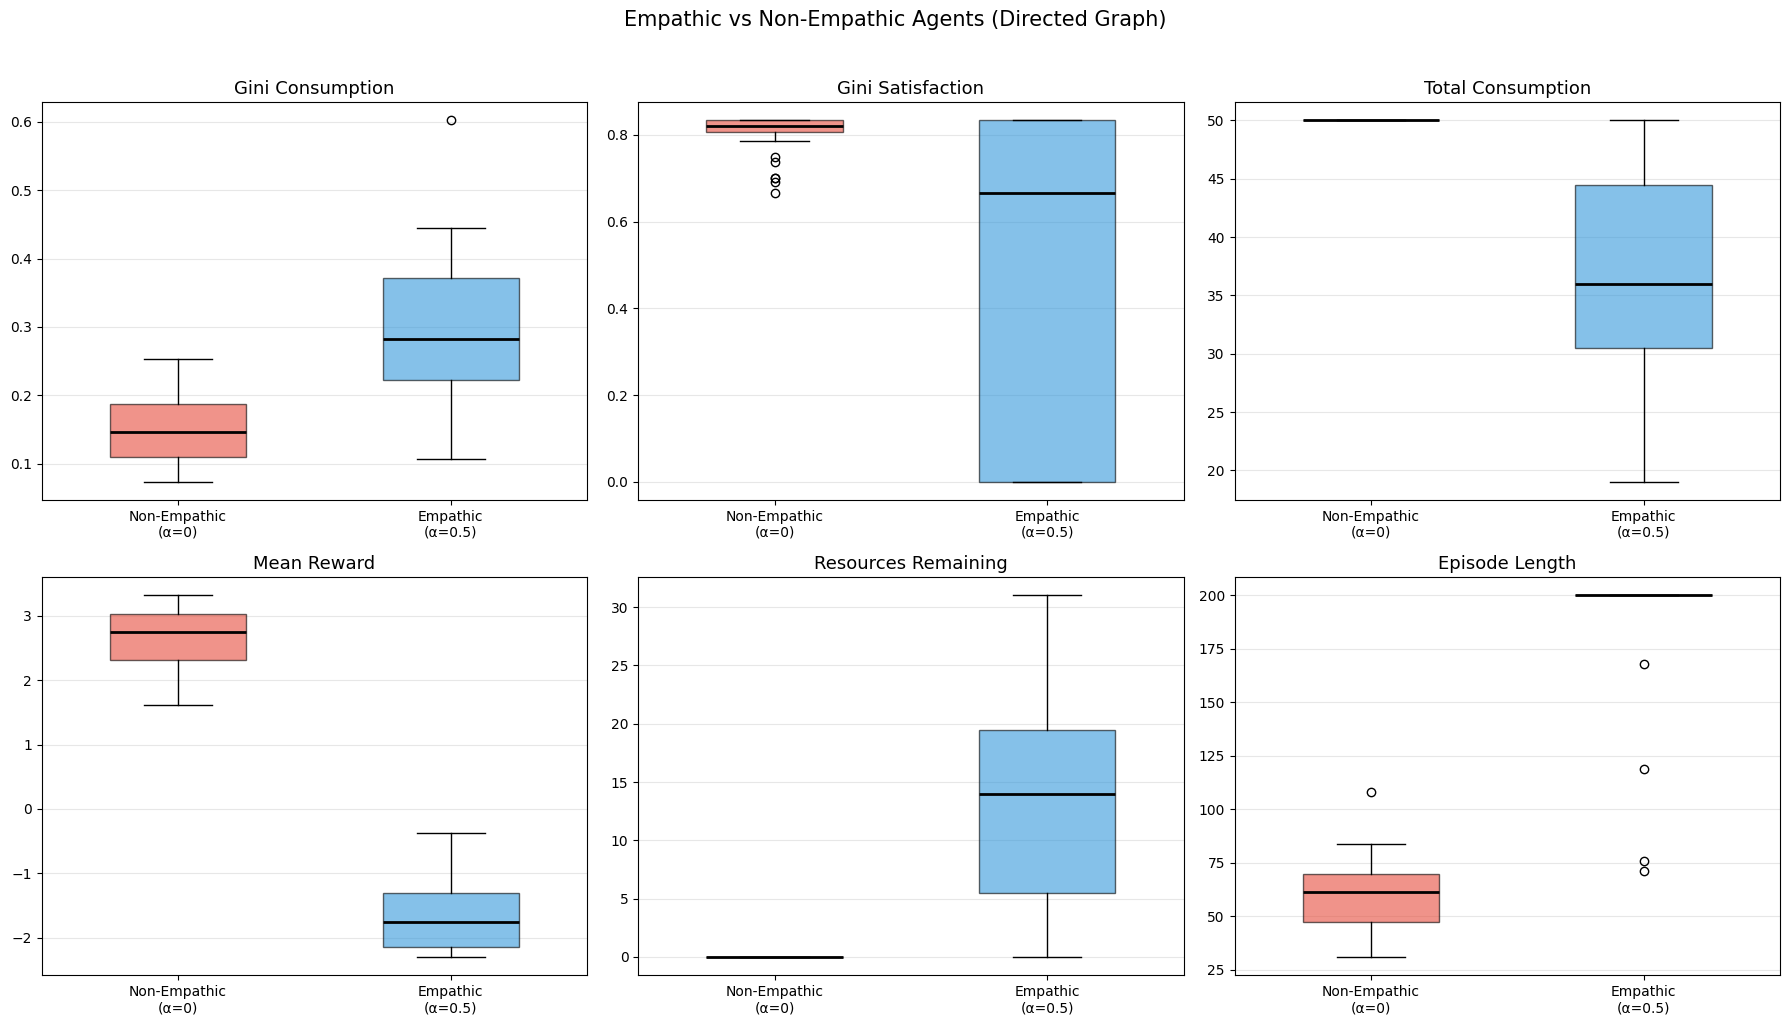

In [9]:
# Box plot comparison of the two conditions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics = {
    'Gini Consumption': gini_consumption,
    'Gini Satisfaction': gini_satisfaction,
    'Total Consumption': total_consumption,
    'Mean Reward': mean_rewards,
    'Resources Remaining': final_pool,
    'Episode Length': episode_length,
}

colors = ['#e74c3c', '#3498db']
labels = ['Non-Empathic\n(α=0)', 'Empathic\n(α=0.5)']

for ax, (title, data) in zip(axes.flatten(), metrics.items()):
    bp = ax.boxplot(
        [data['non_empathic'], data['empathic']],
        labels=labels,
        patch_artist=True,
        widths=0.5,
    )
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    for median in bp['medians']:
        median.set_color('black')
        median.set_linewidth(2)
    ax.set_title(title, fontsize=13)
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Empathic vs Non-Empathic Agents (Directed Graph)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import mannwhitneyu

def eta_squared_from_U(U, n1, n2):
    """Compute eta-squared (effect size) from Mann-Whitney U statistic."""
    r = 1 - (2 * U) / (n1 * n2)
    return r ** 2

print("=" * 75)
print("STATISTICAL COMPARISON  (Mann-Whitney U, two-sided)")
print("=" * 75)

all_metric_names = [
    'Gini Consumption', 'Gini Satisfaction', 'Total Consumption',
    'Mean Reward', 'Resources Remaining', 'Episode Length',
]
all_metric_data = [
    gini_consumption, gini_satisfaction, total_consumption,
    mean_rewards, final_pool, episode_length,
]

for name, data in zip(all_metric_names, all_metric_data):
    ne = np.array(data['non_empathic'])
    em = np.array(data['empathic'])

    U, p = mannwhitneyu(ne, em, alternative='two-sided')
    eta2 = eta_squared_from_U(U, len(ne), len(em))
    diff = np.mean(em) - np.mean(ne)
    pct  = 100 * diff / np.abs(np.mean(ne)) if np.mean(ne) != 0 else float('nan')

    sig = ''
    if p < 0.001:   sig = '***'
    elif p < 0.01:  sig = '**'
    elif p < 0.05:  sig = '*'

    print(f"\n{name}:")
    print(f"  Non-Empathic : {np.mean(ne):.4f}  +/- {np.std(ne):.4f}")
    print(f"  Empathic     : {np.mean(em):.4f}  +/- {np.std(em):.4f}")
    print(f"  Diff (E - NE): {diff:+.4f}  ({pct:+.1f}%)")
    print(f"  U = {U:.1f},  p = {p:.4f} {sig},  eta² = {eta2:.4f}")

STATISTICAL COMPARISON  (Mann-Whitney U, two-sided)

Gini Consumption:
  Non-Empathic : 0.1524  +/- 0.0485
  Empathic     : 0.3023  +/- 0.1099
  Diff (E - NE): +0.1498  (+98.3%)
  U = 88.0,  p = 0.0000 ***,  eta² = 0.6471

Gini Satisfaction:
  Non-Empathic : 0.7993  +/- 0.0494
  Empathic     : 0.4618  +/- 0.3850
  Diff (E - NE): -0.3375  (-42.2%)
  U = 601.0,  p = 0.0236 *,  eta² = 0.1126

Total Consumption:
  Non-Empathic : 50.0000  +/- 0.0000
  Empathic     : 37.4000  +/- 8.7163
  Diff (E - NE): -12.6000  (-25.2%)
  U = 840.0,  p = 0.0000 ***,  eta² = 0.7511

Mean Reward:
  Non-Empathic : 2.6608  +/- 0.4530
  Empathic     : -1.6643  +/- 0.4978
  Diff (E - NE): -4.3251  (-162.5%)
  U = 900.0,  p = 0.0000 ***,  eta² = 1.0000

Resources Remaining:
  Non-Empathic : 0.0000  +/- 0.0000
  Empathic     : 12.6000  +/- 8.7163
  Diff (E - NE): +12.6000  (+nan%)
  U = 60.0,  p = 0.0000 ***,  eta² = 0.7511

Episode Length:
  Non-Empathic : 60.2000  +/- 17.0106
  Empathic     : 187.8000  +/- 34.22